# Semi-graphical Hückel method starting from a SMILES

We start from a **full SMILES** (sigma skeleton + pi system). The `huckel.py` module:

1. automatically detects the atoms of the conjugated pi system (RDKit),
2. assigns parameters (`h_X`, `k_C-X`) to heteroatoms (pyridine-like/pyrrole-like N, ether/carbonyl O, etc.) -- **Van Catledge** by default, or **Streitwieser** via `parameter_set="streitwieser"`,
3. diagonalizes the Hückel matrix,
4. fills the MOs (Aufbau + Hund's rule),
5. plots the energy diagram and the MO coefficients on the molecule's actual geometry.

In [1]:
%matplotlib inline
from pyphyschemtools import HMO


## 1. Benzene -- reference case

Check: x = 2, 1, 1, −1, −1, −2 (exact textbook result).

In [2]:
benzene = HMO('c1ccccc1')
benzene.summary()


SMILES: c1ccccc1
Pi atoms (6): C0:1, C1:1, C2:1, C3:1, C4:1, C5:1
Pi electrons: 6
Total pi energy: E_pi = 6α + 8.0000β
Atomization energy: E_at = 8.0000β
Conjugation energy: E_conj = 2.0000β

 mo_index  x_beta  occupation     role
        5    -2.0         0.0  virtual
        4    -1.0         0.0     LUMO
        3    -1.0         0.0     LUMO
        2     1.0         2.0     HOMO
        1     1.0         2.0     HOMO
        0     2.0         2.0 occupied


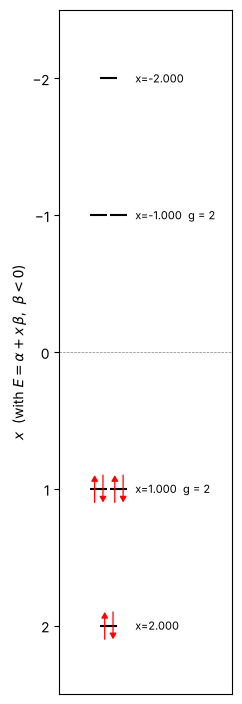

In [3]:
benzene.plot_energy_diagram()


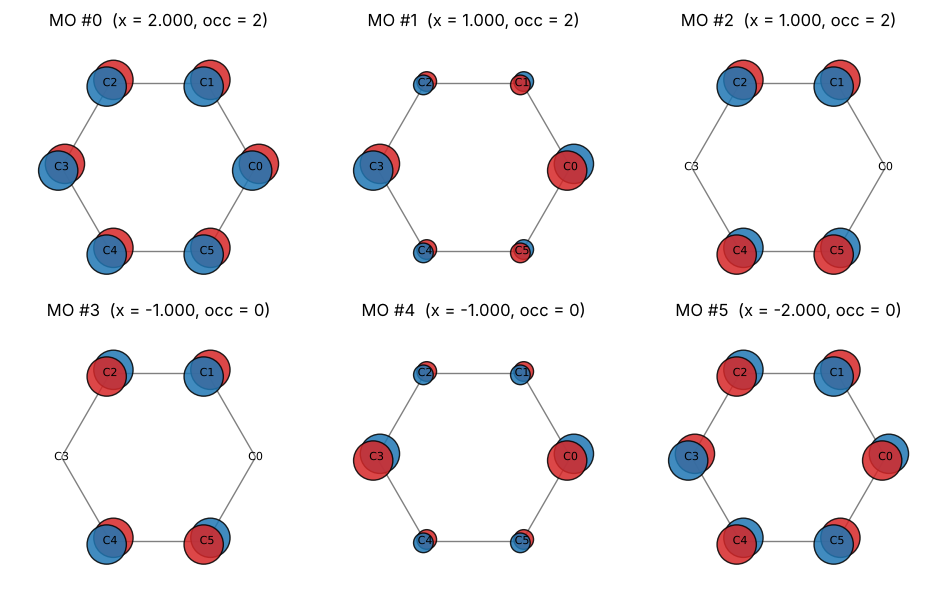

In [4]:
benzene.plot_all_mo()


## 2. A heterocycle: pyridine

The pyridine-type nitrogen has its lone pair in the plane (not in the pi system): it contributes only 1 pi electron, like a carbon, but with `h_N = 0.5`.

In [5]:
pyridine = HMO('c1ccncc1')
pyridine.summary()


SMILES: c1ccncc1
Pi atoms (6): C0:1, C1:1, C2:1, N3:1, C4:1, C5:1
Pi electrons: 6
Total pi energy: E_pi = 6α + 8.6136β
Atomization energy: E_at = 8.1036β
Conjugation energy: E_conj = 2.0008β

 mo_index    x_beta  occupation     role
        5 -1.942925         0.0  virtual
        4 -1.000000         0.0  virtual
        3 -0.853851         0.0     LUMO
        2  1.000000         2.0     HOMO
        1  1.178891         2.0 occupied
        0  2.127885         2.0 occupied


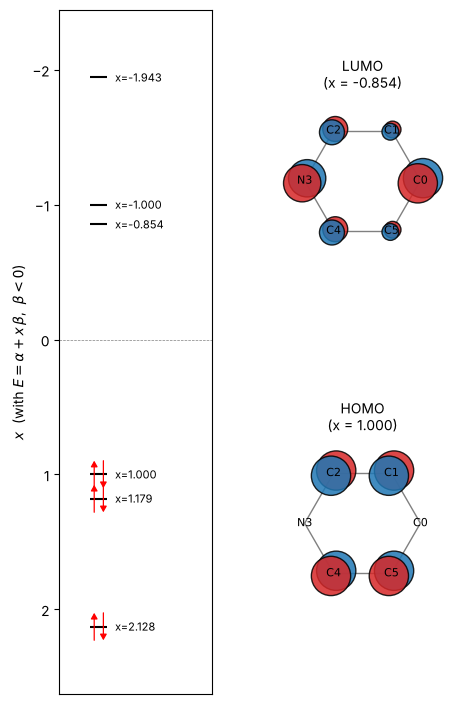

In [6]:
pyridine.plot_energy_diagram('FMO')


## 3. Pyrrole: the nitrogen contributes 2 electrons

Here the nitrogen is pyrrole-like (bonded to 3 atoms including H): its lone pair is perpendicular to the ring, in the pi system -> 2 electrons, `h_N = 1.5`, `k_{C-N} = 0.8`.

SMILES: c1cc[nH]c1
Pi atoms (5): C0:1, C1:1, C2:1, N3:2, C4:1
Pi electrons: 6
Total pi energy: E_pi = 6α + 8.1997β
Atomization energy: E_at = 5.4597β
Conjugation energy: E_conj = 1.4597β

 mo_index    x_beta  occupation     role
        4 -1.618034         0.0  virtual
        3 -1.111838         0.0     LUMO
        2  0.618034         2.0     HOMO
        1  1.129561         2.0 occupied
        0  2.352277         2.0 occupied


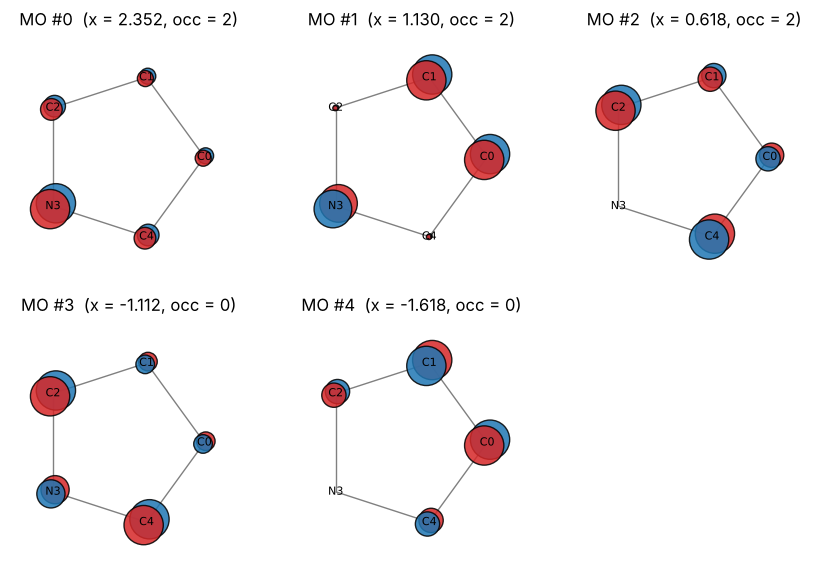

In [7]:
pyrrole = HMO('c1cc[nH]c1')
pyrrole.summary()
pyrrole.plot_all_mo()


## 4. Aromatic ions: cyclopentadienyl (anion) and tropylium (cation)

Same carbon skeleton, but the charged carbon changes the number of pi electrons it contributes (2 for the anion, 0 for the cation) -> 6 pi electrons in both cases, aromaticity, closed shell.

In [8]:
cp_anion = HMO('[cH-]1cccc1')
cp_anion.summary()

tropylium = HMO('[cH+]1cccccc1')
tropylium.summary()


SMILES: [cH-]1cccc1
Pi atoms (5): C0:2, C1:1, C2:1, C3:1, C4:1
Pi electrons: 6
Total pi energy: E_pi = 6α + 6.4721β
Atomization energy: E_at = 6.4721β
Conjugation energy: E_conj = 2.4721β

 mo_index    x_beta  occupation     role
        4 -1.618034         0.0     LUMO
        3 -1.618034         0.0     LUMO
        2  0.618034         2.0     HOMO
        1  0.618034         2.0     HOMO
        0  2.000000         2.0 occupied
SMILES: [cH+]1cccccc1
Pi atoms (7): C0:0, C1:1, C2:1, C3:1, C4:1, C5:1, C6:1
Pi electrons: 6
Total pi energy: E_pi = 6α + 8.9879β
Atomization energy: E_at = 8.9879β
Conjugation energy: E_conj = 2.9879β

 mo_index    x_beta  occupation     role
        6 -1.801938         0.0  virtual
        5 -1.801938         0.0  virtual
        4 -0.445042         0.0     LUMO
        3 -0.445042         0.0     LUMO
        2  1.246980         2.0     HOMO
        1  1.246980         2.0     HOMO
        0  2.000000         2.0 occupied


**Delocalized pi charge -- reference to the neutral carbon.** To compute `pi_charge`, the formally charged carbon (`("C","anion")`/`("C","cation")`) is compared to a **neutral** carbon (1 pi electron), not to its own "ionized" electron count (2 or 0): otherwise that same atom would have its formal charge subtracted off once via its own reference, and then a second time via the delocalized density -- which, by symmetry, can flip its apparent sign outright (the nominally cationic carbon of tropylium would come out negatively charged!). With the correct reference, the system's overall +1/-1 charge is distributed correctly, uniformly here by symmetry:

In [9]:
import numpy as np
print("cyclopentadienyl (anion), pi charge per atom:", np.round(cp_anion.pi_charge, 3),
      "-- sum =", round(cp_anion.pi_charge.sum(), 3))
print("tropylium (cation), pi charge per atom       :", np.round(tropylium.pi_charge, 3),
      "-- sum =", round(tropylium.pi_charge.sum(), 3))

cyclopentadienyl (anion), pi charge per atom: [-0.2 -0.2 -0.2 -0.2 -0.2] -- sum = -1.0
tropylium (cation), pi charge per atom       : [0.143 0.143 0.143 0.143 0.143 0.143 0.143] -- sum = 1.0


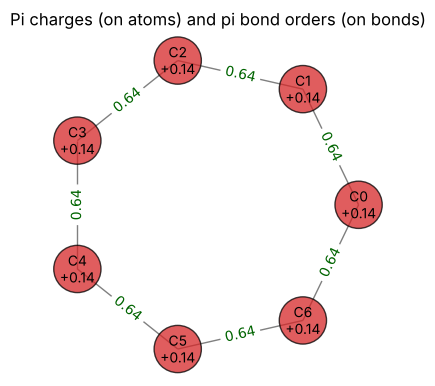

In [10]:
tropylium.plot_pi_population()

## 5. Degeneracy and Hund's rule: cyclobutadiene

Antiaromatic system (4 pi electrons, D4h): the two non-bonding MOs are degenerate (x = 0) and each gets filled with a single electron (triplet ground state), not a pair plus an empty slot.

SMILES: C1=CC=C1
Pi atoms (4): C0:1, C1:1, C2:1, C3:1
Pi electrons: 4
Total pi energy: E_pi = 4α + 4.0000β
Atomization energy: E_at = 4.0000β
Conjugation energy: E_conj = 0.0000β

 mo_index  x_beta  occupation     role
        3    -2.0         0.0     LUMO
        2     0.0         1.0     SOMO
        1     0.0         1.0     SOMO
        0     2.0         2.0 occupied


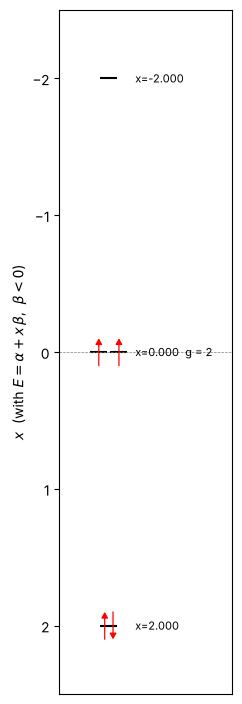

In [11]:
cbd = HMO('C1=CC=C1')
cbd.summary()
cbd.plot_energy_diagram()


## 6. Forcing a parameter or an electron count (overrides)

The classification heuristics (degree, H count, aromaticity) cover the usual cases but not everything. You can always force `h_X` for an atom, `k_C-X` for a bond, or the number of pi electrons of an atom, by giving the atom's RDKit index (visible in `.labels` after a first build, or with `mol.GetAtomWithIdx(i)` / an RDKit drawing).

In [12]:
# Example: force a different h_N for pyridine (sensitivity of the results to the parameter)
pyridine_h1 = HMO('c1ccncc1', h_overrides={3: 1.0})
pyridine_h1.summary()

SMILES: c1ccncc1
Pi atoms (6): C0:1, C1:1, C2:1, N3:1, C4:1, C5:1
Pi electrons: 6
Total pi energy: E_pi = 6α + 9.2413β
Atomization energy: E_at = 8.2413β
Conjugation energy: E_conj = 1.9694β

 mo_index    x_beta  occupation     role
        5 -1.899309         0.0  virtual
        4 -1.000000         0.0  virtual
        3 -0.721335         0.0     LUMO
        2  1.000000         2.0     HOMO
        1  1.320746         2.0 occupied
        0  2.299898         2.0 occupied


For a GLOBAL charge on the pi system (not tied to a specific atom), there is no need to write a carbocation/carbanion in the SMILES (which would additionally pin the extra/missing electron to ONE particular atom -- see the previous section, allyl cation/tropylium, for why it always ends up delocalized anyway): the `charge` keyword at construction is enough -- the usual chemical convention, a positive `charge` removes pi electrons (cation), a negative one adds them (anion).

In [13]:
benzene_dication = HMO("c1ccccc1", charge=2)   # two fewer pi electrons
benzene_dication.summary()

SMILES: c1ccccc1
Pi atoms (6): C0:1, C1:1, C2:1, C3:1, C4:1, C5:1
Global charge (charge=): +2
Pi electrons: 4
Total pi energy: E_pi = 4α + 6.0000β
Atomization energy: E_at = 6.0000β
Conjugation energy: E_conj = 0.0000β

 mo_index  x_beta  occupation     role
        5    -2.0         0.0  virtual
        4    -1.0         0.0     LUMO
        3    -1.0         0.0     LUMO
        2     1.0         1.0     SOMO
        1     1.0         1.0     SOMO
        0     2.0         2.0 occupied


In [14]:
benzene_dianion = HMO("c1ccccc1", charge=-2)   # two extra pi electrons
print(benzene_dianion.n_pi_electrons, "pi electrons -- pi charge per atom:",
      benzene_dianion.pi_charge.round(3), "-- sum =", round(benzene_dianion.pi_charge.sum(), 3))

8 pi electrons -- pi charge per atom: [-0.333 -0.333 -0.333 -0.333 -0.333 -0.333] -- sum = -2.0


## 7. Your own SMILES

Replace the SMILES below (a conjugated molecule, carbonyl, heterocycle...) and rerun.

SMILES: O=Cc1ccccc1
Pi atoms (8): O0:1, C1:1, C2:1, C3:1, C4:1, C5:1, C6:1, C7:1
Pi electrons: 8
Total pi energy: E_pi = 8α + 11.7508β
Atomization energy: E_at = 10.7808β
Conjugation energy: E_conj = 2.4494β

 mo_index    x_beta  occupation     role
        7 -2.126229         0.0  virtual
        6 -1.355013         0.0  virtual
        5 -1.000000         0.0  virtual
        4 -0.424144         0.0     LUMO
        3  0.993033         2.0     HOMO
        2  1.000000         2.0 occupied
        1  1.687365         2.0 occupied
        0  2.194988         2.0 occupied


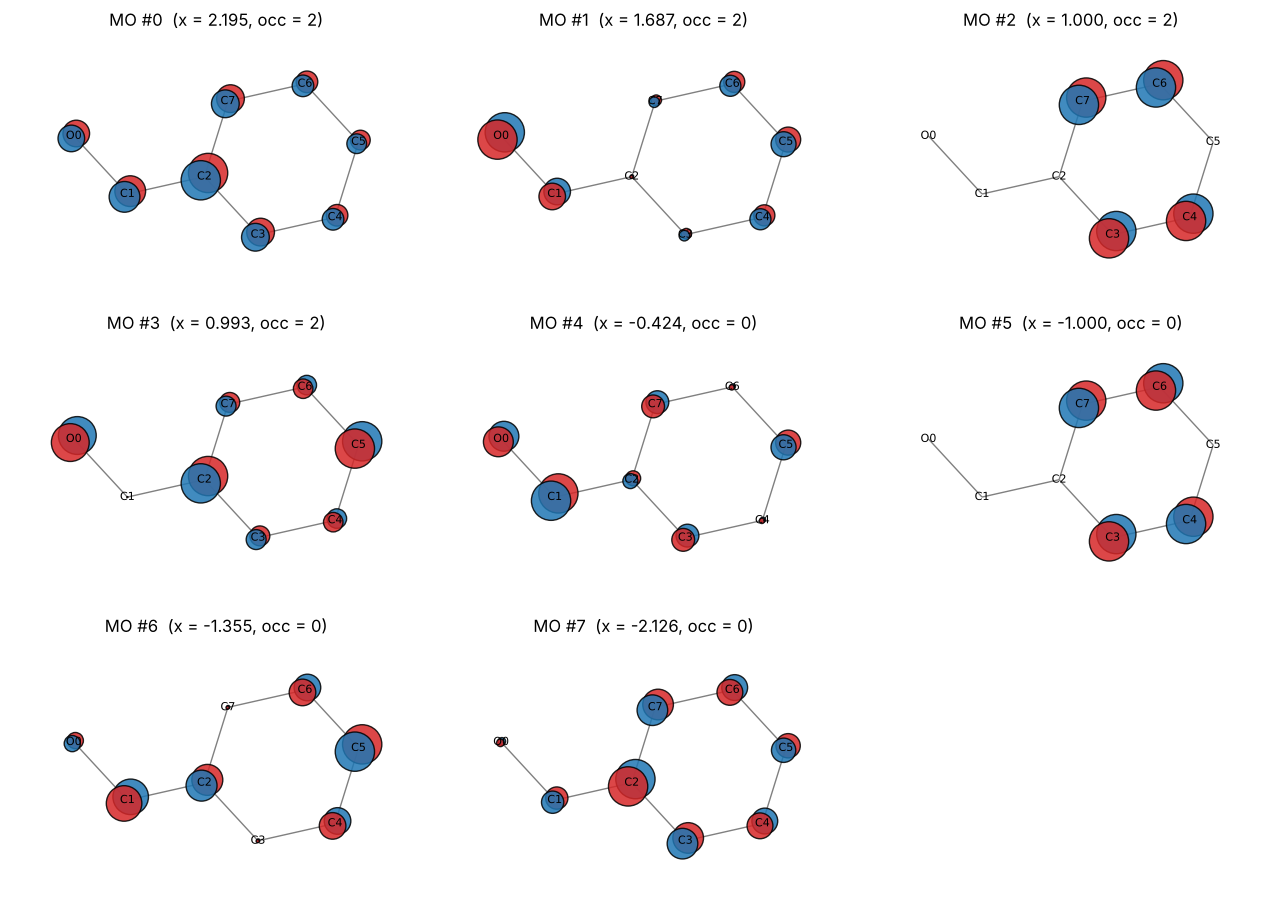

In [15]:
mol = HMO('O=Cc1ccccc1')  # benzaldehyde
mol.summary()
mol.plot_all_mo()

## 8. Listing the MOs, pi charges / bond orders

`mo_table()` gives the MO table (like `summary()`, but as a DataFrame, handy for filtering/sorting). `plot_pi_population()` draws the classic charge + pi-bond-order diagram. `density_matrix()` gives the density matrix P (P_rr = electron density on atom r, P_rs = pi bond order between r and s).

In [16]:
pyridine.mo_table()


,mo_index,x_beta,occupation,role,C0,C1,C2,N3,C4,C5
0,5,-1.943,0.000,virtual,-0.447,0.434,-0.397,0.330,-0.397,0.434
1,4,-1.000,0.000,virtual,0.000,0.500,-0.500,0.000,0.500,-0.500
2,3,-0.854,0.000,LUMO,0.570,-0.243,-0.362,0.542,-0.362,-0.243
3,2,1.000,2.000,HOMO,0.000,-0.500,-0.500,0.000,0.500,0.500
4,1,1.179,2.000,occupied,0.603,0.356,-0.184,-0.561,-0.184,0.356
5,0,2.128,2.000,occupied,-0.333,-0.355,-0.421,-0.531,-0.421,-0.355


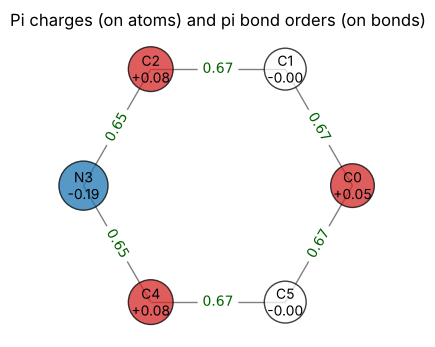

In [17]:
pyridine.plot_pi_population()


In [18]:
pyridine.density_matrix()


,C0,C1,C2,N3,C4,C5
C0,0.950,0.666,0.059,-0.323,0.059,0.666
C1,0.666,1.005,0.668,-0.023,-0.332,0.005
C2,0.059,0.668,0.923,0.654,-0.077,-0.332
N3,-0.323,-0.023,0.654,1.195,0.654,-0.023
C4,0.059,-0.332,-0.077,0.654,0.923,0.668
C5,0.666,0.005,-0.332,-0.023,0.668,1.005


## 9. Reactivity descriptors (HOMO/LUMO, hardness...) as a DataFrame

`properties()` returns a dict (HOMO/LUMO energies, gap, hardness, softness, chemical potential, electronegativity, electrophilicity) ready to use directly. `hmo_properties_table()` does the same for a list of SMILES and returns a ready-to-use DataFrame.

In [19]:
pyridine.properties()


{'smiles': 'c1ccncc1',
 'n_pi_atoms': 6,
 'n_pi_electrons': 6,
 'homo_index': 2,
 'lumo_index': 3,
 'E_HOMO': 1.0,
 'E_LUMO': -0.8538514423052634,
 'gap': 1.8538514423052634,
 'hardness': 0.9269257211526317,
 'softness': 0.5394175483427628,
 'chemical_potential': 0.07307427884736828,
 'electronegativity': -0.07307427884736828,
 'electrophilicity': 0.002880408919078669,
 'total_pi_energy': 8.613552993478168,
 'atomization_energy': 8.103552993478168,
 'conjugation_energy': np.float64(2.0007691244131607)}

In [20]:
from pyphyschemtools import hmo_properties_table

df = hmo_properties_table(['c1ccccc1', 'c1ccncc1', 'c1cc[nH]c1', 'c1ccoc1', 'C=CC=C'])
df


,smiles,n_pi_atoms,n_pi_electrons,homo_index,lumo_index,E_HOMO,E_LUMO,gap,hardness,softness,chemical_potential,electronegativity,electrophilicity,total_pi_energy,atomization_energy,conjugation_energy
0,c1ccccc1,6,6,2,3,1.000000,-1.000000,2.000000,1.000000,0.500000,0.000000e+00,-0.000000e+00,0.000000e+00,8.000000,8.000000,2.000000
1,c1ccncc1,6,6,2,3,1.000000,-0.853851,1.853851,0.926926,0.539418,7.307428e-02,-7.307428e-02,2.880409e-03,8.613553,8.103553,2.000769
2,c1cc[nH]c1,5,6,2,3,0.618034,-1.111838,1.729872,0.864936,0.578077,-2.469021e-01,2.469021e-01,3.523998e-02,8.199745,5.459745,1.459745
3,c1ccoc1,5,6,2,3,0.618034,-0.840584,1.458618,0.729309,0.685580,-1.112752e-01,1.112752e-01,8.488967e-03,9.097237,4.917237,0.917237
4,C=CC=C,4,4,1,2,0.618034,-0.618034,1.236068,0.618034,0.809017,3.330669e-16,-3.330669e-16,8.974714e-32,4.472136,4.472136,0.472136


## 10. Pi atomization energy

`total_pi_energy()` is the total energy of the delocalized pi electrons. `atomization_energy()` compares it to the reference where those same electrons would stay localized, non-interacting, on their original atoms (each at its own Coulomb level alpha_r). For an all-carbon system (h=0 everywhere), this reference is zero and the atomization energy coincides with the total pi energy; the gap between the two becomes significant as soon as a heteroatom (h != 0) is present.

In [21]:
print('Benzene:', benzene.atomization_energy(), '|beta|')
print('Pyridine:', pyridine.atomization_energy(), '|beta|', '  (total pi energy =', pyridine.total_pi_energy(), ')')

Benzene: 8.0 |beta|
Pyridine: 8.103552993478168 |beta|   (total pi energy = 8.613552993478168 )


## 11. Pi conjugation (resonance) energy, relative to a Kekule structure

`atomization_energy()` compares the delocalized pi system to fully isolated, non-interacting atoms. `conjugation_energy()` (and the stored `.E_conjugation`) uses a different, more specific reference: a localized Kekule structure, i.e. each formal pi double bond treated as its own isolated, localized 2-center bond (reducing to the textbook alpha+beta level for a plain C=C, generalized to a heteroatom-involving double bond such as pyridine's C=N by diagonalizing just that 2x2 block), and every atom left unpaired by that Kekule structure (a lone pair localized on a single center, e.g. pyrrole-type N) kept at its own isolated-atom level, exactly as in `atomization_energy()`.

This is the classic "resonance energy" of textbooks: benzene's is 2|beta|. Cyclobutadiene is the interesting edge case: its localized Kekule structure (two isolated C=C double bonds) is already as stable as the delocalized, antiaromatic ring, so its conjugation energy comes out to (near) zero.


In [22]:
print('Benzene:', benzene.conjugation_energy(), '|beta|')
print('Pyrrole:', pyrrole.conjugation_energy(), '|beta|')
print('Pyridine:', pyridine.conjugation_energy(), '|beta|', '  (local 2x2 handles the C=N double bond)')

cyclobutadiene = HMO('C1=CC=C1')
print('Cyclobutadiene:', round(cyclobutadiene.conjugation_energy(), 6), '|beta|', '  (antiaromatic: no stabilization over its own localized Kekule structure)')


Benzene: 2.0 |beta|
Pyrrole: 1.4597445402687637 |beta|
Pyridine: 2.0007691244131607 |beta|   (local 2x2 handles the C=N double bond)
Cyclobutadiene: 0.0 |beta|   (antiaromatic: no stabilization over its own localized Kekule structure)


## 12. Edge case: C60 (icosahedral)

A good robustness test: the C60 fullerene has 60 carbon atoms, all of degree 3, forming a closed cage (12 pentagons + 20 hexagons). The Hückel spectrum shows high degeneracies (up to order 9 here), some beyond what the Ih point-group symmetry alone predicts (so-called "accidental" degeneracies, a known phenomenon for this graph). The result lands exactly on the usual description of C60: closed-shell system, 5-fold degenerate HOMO (hu type), 3-fold degenerate LUMO (t1u type), small HOMO-LUMO gap.

In [23]:
c60_smiles = (
    'C12=C3C4=C5C6=C1C7=C8C9=C1C%10=C%11C(=C29)C3=C2C3=C4C4=C5C5=C9C6=C7'
    'C6=C7C8=C1C1=C8C%10=C%10C%11=C2C2=C3C3=C4C4=C5C5=C%11C%12=C(C6=C95)'
    'C7=C1C1=C%12C5=C%11C4=C3C3=C5C(=C81)C%10=C23'
)
c60 = HMO(c60_smiles)
print('pi atoms:', len(c60.pi_atom_idx), '  pi electrons:', c60.n_pi_electrons)
c60.properties()


pi atoms: 60   pi electrons: 60


{'smiles': 'C12=C3C4=C5C6=C1C7=C8C9=C1C%10=C%11C(=C29)C3=C2C3=C4C4=C5C5=C9C6=C7C6=C7C8=C1C1=C8C%10=C%10C%11=C2C2=C3C3=C4C4=C5C5=C%11C%12=C(C6=C95)C7=C1C1=C%12C5=C%11C4=C3C3=C5C(=C81)C%10=C23',
 'n_pi_atoms': 60,
 'n_pi_electrons': 60,
 'homo_index': 29,
 'lumo_index': 30,
 'E_HOMO': 0.6180339887498932,
 'E_LUMO': -0.13856426511017253,
 'gap': 0.7565982538600657,
 'hardness': 0.37829912693003287,
 'softness': 1.3217054029640305,
 'chemical_potential': 0.23973486181986037,
 'electronegativity': -0.23973486181986037,
 'electrophilicity': 0.07596211553300418,
 'total_pi_energy': 93.16160379436798,
 'atomization_energy': 93.16160379436798,
 'conjugation_energy': np.float64(33.16160379436798)}

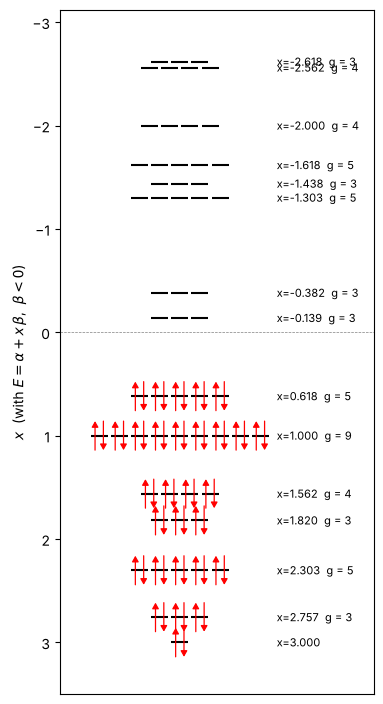

In [24]:
c60.plot_energy_diagram()  # width auto-scaled to the degeneracy order

## 13. Hückel matrix (numeric and symbolic)

`huckel_matrix()` returns the dimensionless matrix M such that H = alpha*I + beta*M. By default it is numeric; with `symbolic=True`, the entries are shown literally in terms of `alpha`/`beta` (via sympy if available).

`summary()` now also shows the number of pi electrons contributed by each atom (`C0:1, C1:1, ...`), as well as the total, atomization and conjugation energies. All three are also stored as attributes (`.E_total`, `.E_atomization`, `.E_conjugation`) for direct reuse, e.g. in a DataFrame.

In [25]:
pyridine.summary()


SMILES: c1ccncc1
Pi atoms (6): C0:1, C1:1, C2:1, N3:1, C4:1, C5:1
Pi electrons: 6
Total pi energy: E_pi = 6α + 8.6136β
Atomization energy: E_at = 8.1036β
Conjugation energy: E_conj = 2.0008β

 mo_index    x_beta  occupation     role
        5 -1.942925         0.0  virtual
        4 -1.000000         0.0  virtual
        3 -0.853851         0.0     LUMO
        2  1.000000         2.0     HOMO
        1  1.178891         2.0 occupied
        0  2.127885         2.0 occupied


In [26]:
print("E_total:", pyridine.E_total, "|beta|")
print("E_atomization:", pyridine.E_atomization, "|beta|")
print("E_conjugation:", pyridine.E_conjugation, "|beta|")


E_total: 8.613552993478168 |beta|
E_atomization: 8.103552993478168 |beta|
E_conjugation: 2.0007691244131607 |beta|


In [27]:
pyridine.huckel_matrix(symbolic=False)


,C0,C1,C2,N3,C4,C5
C0,0.000,1.000,0.000,0.000,0.000,1.000
C1,1.000,0.000,1.000,0.000,0.000,0.000
C2,0.000,1.000,0.000,1.020,0.000,0.000
N3,0.000,0.000,1.020,0.510,1.020,0.000
C4,0.000,0.000,0.000,1.020,0.000,1.000
C5,1.000,0.000,0.000,0.000,1.000,0.000


In [28]:
pyridine.huckel_matrix(symbolic=True)


,C0,C1,C2,N3,C4,C5
C0,α,β,0,0,0,β
C1,β,α,β,0,0,0
C2,0,β,α,1.02*β,0,0
N3,0,0,1.02*β,α + 0.51*β,1.02*β,0
C4,0,0,0,1.02*β,α,β
C5,β,0,0,0,β,α


## 14. Van Catledge parameter table, free valence

`parameter_set` is chosen per molecule (an argument to `HMO(...)`), not once for the whole session -- nothing stops you from mixing the two parameter sets in the same notebook, as below (`pyridine_vc` explicitly asks for Van Catledge again, already the default for `pyridine` above, just for comparison -- passing `parameter_set="streitwieser"` would give the other set).

Van Catledge (the default, F. A. Van-Catledge, *J. Org. Chem.* 1980, 45 (24), 4801-4802, derived from PPP calculations) is the richer table: it additionally covers B, Si, P, and gives a full `k_XY` matrix between any two heteroatoms (Streitwieser, `parameter_set="streitwieser"`, only tabulates bonds to a carbon). It also provides a reference free valence `Fx` per atom type, used to compute the free-valence index (radical reactivity) `.free_valence`.

`parameter_table(parameter_set)` shows the full table; `.used_parameters()` shows only the parameters actually used by a given molecule.

In [29]:
from pyphyschemtools import parameter_table

parameter_table("van_catledge")


,symbol,kind,h,k_to_C,n_pi,Fx
0,C,sp2,0.00,1.00,1,1.732
1,C,anion,0.00,1.00,2,1.732
2,C,cation,0.00,1.00,0,1.732
3,B,vacant,-0.45,0.73,0,1.705
4,N,pyridine,0.51,1.02,1,1.393
5,N,pyrrole,1.37,0.89,2,1.583
6,O,carbonyl,0.97,1.06,1,0.909
7,O,furan,2.09,0.66,2,0.942
8,F,halogen,2.71,0.52,2,0.179
9,Si,sp2,0.00,0.75,1,1.732


In [30]:
pyridine_vc = HMO("c1ccncc1", parameter_set="van_catledge")
pyridine_vc.used_parameters()


,parameter_set,symbol,kind,h,k_to_C,n_pi,Fx
0,van_catledge,C,sp2,0.000,1.000,1,1.732
1,van_catledge,N,pyridine,0.510,1.020,1,1.393


In [31]:
pyridine_vc.free_valence


array([0.4007567 , 0.39844948, 0.40967355, 0.08420484, 0.40967355,
       0.39844948])

In [32]:
# a phosphole (P instead of the pyrrole-type N) -- impossible with Streitwieser alone
phosphole = HMO("c1cc[pH]c1", parameter_set="van_catledge")
phosphole.summary()

SMILES: c1cc[pH]c1
Pi atoms (5): C0:1, C1:1, C2:1, P3:2, C4:1
Pi electrons: 6
Total pi energy: E_pi = 6α + 6.9369β
Atomization energy: E_at = 5.4369β
Conjugation energy: E_conj = 1.4369β

 mo_index    x_beta  occupation     role
        4 -1.618034         0.0  virtual
        3 -1.100398         0.0     LUMO
        2  0.618034         2.0     HOMO
        1  0.877642         2.0 occupied
        0  1.972757         2.0 occupied


`plot_pi_population()` colors the atoms by the sign of the pi charge (red = positive/electron-poor, blue = negative/electron-rich); a nearly neutral atom (|charge| < 0.01) is drawn in white rather than with a barely visible tint.

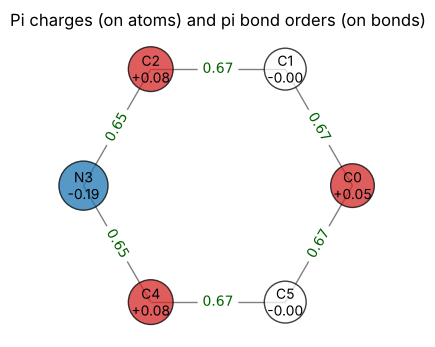

In [33]:
pyridine.plot_pi_population()


## 15. Streitwieser parameters reintroduced: Br, N⁺, O⁺ -- and confirmation for "Me"

The entries `("Br", "halogen")`, `("N", "pyridinium")` (aromatic N⁺, i.e. N-alkylpyridinium type) and `("O", "oxocarbenium")` do come from Streitwieser himself: *Molecular Orbital Theory for Organic Chemists*, 1961, Table 5.3 (p. 135, "Suggested parameter values for heteroatoms") -- h(Br)=1.5/k=0.3, h(N⁺)=2.0, h(O⁺)=2.5.

While revising this table, an inconsistency was fixed along the way: the aromatic N⁺ (e.g. N-alkylpyridinium) was counted as contributing 0 pi electrons (`n_pi=0`) even though it has the same pi bonding pattern as neutral pyridine -- 1 pi electron, with a higher h because of the + charge. It is now classified as `("N", "pyridinium")` with `n_pi=1`.

And the `("C", "methyl_donor")` entry (an exocyclic methyl treated as a pseudo-heteroatom donating 2 pi electrons) is also in that same Table 5.3 -- it is the "heteroatom model" of hyperconjugation (Matsen and Stevenson, Sec. 5.7): `h_X=2`, `k_C-X=0.7`. Its origin, which we hadn't tracked down in Purcell & Singer, is thus indeed Streitwieser -- with a `k` corrected to 0.7 (it was 1.0 by mistake).

In [34]:
parameter_table("streitwieser")


,symbol,kind,h,k_to_C,n_pi
0,C,sp2,0.0,1.0,1
1,C,anion,0.0,1.0,2
2,C,cation,0.0,1.0,0
3,N,pyridine,0.5,1.0,1
4,N,pyrrole,1.5,0.8,2
5,N,pyridinium,2.0,1.0,1
6,O,furan,2.0,0.8,2
7,O,carbonyl,1.0,1.0,1
8,O,oxocarbenium,2.5,1.0,1
9,S,thiophene,1.5,0.6,2


## 16. Drawing a chosen list of MOs

`plot_all_mo()` systematically draws every MO. `plot_mo_list(indices, figsize_per=...)` lets you pick just a few (in the given order), with each panel's size adjustable via `figsize_per` (width, height in inches per MO) -- handy for comparing just a few MOs of interest rather than the whole set.

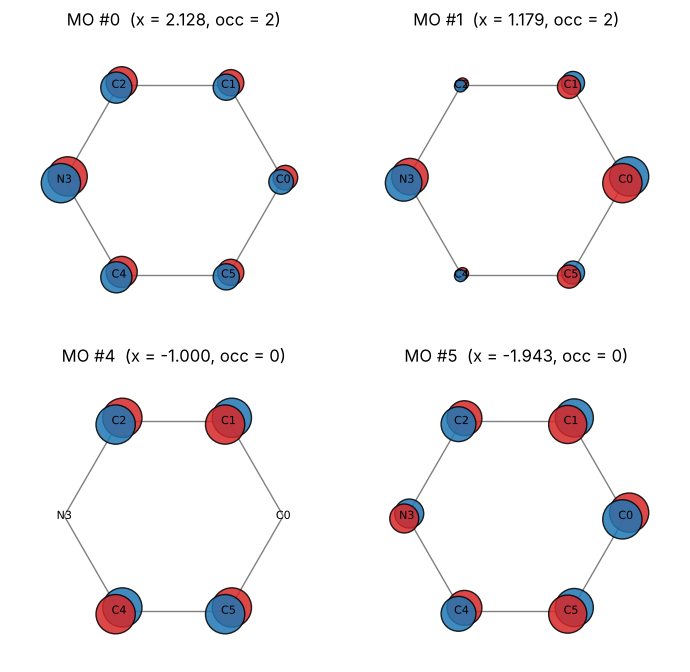

In [35]:
pyridine.plot_mo_list([0, 1, 4, 5], ncols=2, figsize_per=(3.5, 3.5))


## 17. Drawing the molecule's full skeleton

`.show()` draws the molecule the way RDKit would normally depict it (full sigma + pi skeleton, implicit H's...), as opposed to `plot_mo_on_graph` / `plot_pi_population`, which only draw the pi subsystem used for the Hückel treatment.

By default: `show_indices=True` (each atom's RDKit index -- the same one used in `self.pi_atom_idx` and the "C0", "N3"... labels of `self.mo_table()`) and `highlight_pi=True` (highlights the conjugated system actually kept for Hückel -- handy to check at a glance that it was detected correctly, in particular when several pi systems are present but not connected, as below where the -CH2- bridge cuts the conjugation between the two rings). `show_hybridization=True` additionally adds each atom's hybridization state (sp, sp2, sp3).

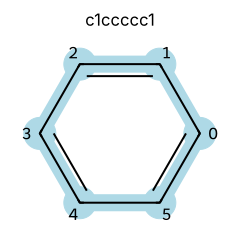

In [36]:
benzene.show()


/tmp/claude-0/-home-claude/39b22db6-d539-5297-8772-4f0a0f2b0ef7/scratchpad/conj_build/_test_shim/pyphyschemtools/huckel.py:710: UserWarning: Atom idx 8 (C, 2 H, 2 heavy-atom neighbour(s)) is a larger alkyl substituent, not a plain methyl -- it is being parametrized with the methyl ('Me') pseudo-heteroatom values (h=2.0, k=0.7), the closest literature-backed approximation available, since no dedicated value exists for larger alkyls. Pass h_overrides/k_overrides/electron_overrides for this atom index if you have a better value, or alkyl_scope='methyl_only' to exclude it instead (and treat it as an inert sigma substituent, outside the pi system, as before).
  warnings.warn(


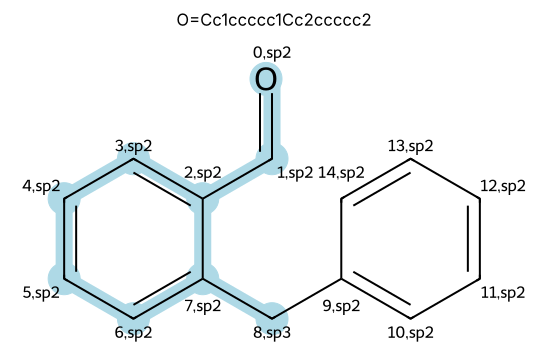

[0, 1, 2, 3, 4, 5, 6, 7, 8] ['O0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'Me8']


In [37]:
# the -CH2- bridge does cut the AROMATIC conjugation between the two rings
# (the second ring is still fully excluded) -- but with
# include_hyperconjugation=True (the default), that same -CH2- also becomes
# a hyperconjugating pseudo-atom for the FIRST ring (see section 18):
# Me8 shows up, hence a warning (an alkyl, not a true methyl)
bridged = HMO("O=Cc1ccccc1Cc2ccccc2")
bridged.show(show_hybridization=True)
print(bridged.pi_atom_idx, bridged.labels)

## 18. Saving figures and tables

Every plotting method (`plot_energy_diagram`, `plot_pi_population`, `plot_mo_on_graph`, `plot_mo_list`/`plot_all_mo`, `.show()`...) accepts a `save_path` (+ `dpi`): the figure is then also saved via `save_fig` -- the same function as `pyphyschemtools.core.save_fig` when `huckel.py` is used from within the package (otherwise an identical local fallback is used, for standalone use).

For tables, `save_data(df, path)` (likewise: reuses `pyphyschemtools.core.save_data` if available) saves a DataFrame as CSV or Excel depending on the extension -- directly usable on `hmo_properties_table(...)`. And `.save_results(path.xlsx)` saves, in a single call, the MO table (coefficients included) and the density matrix together in one multi-sheet Excel/ODS workbook.

Figure saved to: /tmp/tmpsz_sfzr0/benzene_pi.png


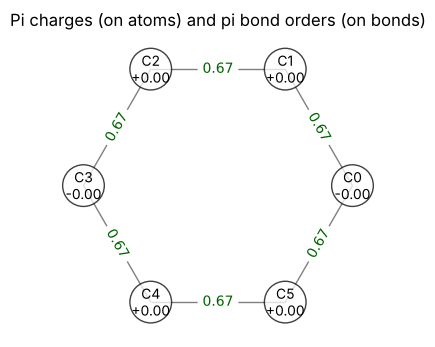

Data saved to: /tmp/tmpsz_sfzr0/properties.xlsx
Results saved to: /tmp/tmpsz_sfzr0/pyridine_results.xlsx  (sheets: MO, density_matrix)


In [38]:
import tempfile, os
tmp = tempfile.mkdtemp()

# a figure
benzene.plot_pi_population(save_path=os.path.join(tmp, "benzene_pi.png"))

# a single table
from pyphyschemtools import save_data
df = hmo_properties_table(["c1ccccc1", "c1ccncc1"])
save_data(df, os.path.join(tmp, "properties.xlsx"))

# MOs + density matrix in a single multi-sheet workbook
pyridine.save_results(os.path.join(tmp, "pyridine_results.xlsx"))

## 19. Hyperconjugation of a methyl/alkyl group attached to the pi system

By default (`include_hyperconjugation=True`), a methyl or alkyl group attached DIRECTLY to the conjugated system (toluene, indane/tetralin...) is included as one more pseudo-heteroatom, contributing a lone pair (the "heteroatom model" of hyperconjugation, Matsen and Stevenson -- see section 14): `("C", "methyl_donor")`, h=2.0, k=0.7. Only the FIRST attached carbon counts as a pseudo-atom -- the rest of an alkyl chain (e.g. the terminal CH3 of an ethyl group) is not modeled any further. A substituent that touches the pi system through TWO atoms (an actual bridge between two rings, as in section 16) stays excluded: that is not a simple substituent, but a genuine break in conjugation.

For a true methyl (-CH3, 3 H's, no other substitution), no warning: this is exactly the case covered by the literature. For a larger alkyl (-CH2R, -CHR2...), the methyl's value is reused as an approximation and a warning flags it, along with how to correct it (`h_overrides`/`k_overrides`/`electron_overrides` for that atom) or exclude it (`alkyl_scope="methyl_only"`).

In [39]:
toluene = HMO("c1ccccc1C")  # true methyl: no warning
toluene.summary()

SMILES: c1ccccc1C
Pi atoms (7): C0:1, C1:1, C2:1, C3:1, C4:1, C5:1, Me6:2
Pi electrons: 8
Total pi energy: E_pi = 8α + 12.1508β
Atomization energy: E_at = 8.1508β
Conjugation energy: E_conj = 2.1508β

 mo_index    x_beta  occupation     role
        6 -2.021563         0.0  virtual
        5 -1.053836         0.0  virtual
        4 -1.000000         0.0     LUMO
        3  0.861888         2.0     HOMO
        2  1.000000         2.0 occupied
        1  1.821256         2.0 occupied
        0  2.392255         2.0 occupied


In [40]:
# ethylbenzene: the -CH2- attached to the ring is not a true methyl
# -> warning, methyl's value reused as an approximation
ethylbenzene = HMO("c1ccccc1CC")
print(ethylbenzene.labels)

['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'Me6']


/tmp/claude-0/-home-claude/39b22db6-d539-5297-8772-4f0a0f2b0ef7/scratchpad/conj_build/_test_shim/pyphyschemtools/huckel.py:710: UserWarning: Atom idx 6 (C, 2 H, 2 heavy-atom neighbour(s)) is a larger alkyl substituent, not a plain methyl -- it is being parametrized with the methyl ('Me') pseudo-heteroatom values (h=2.0, k=0.7), the closest literature-backed approximation available, since no dedicated value exists for larger alkyls. Pass h_overrides/k_overrides/electron_overrides for this atom index if you have a better value, or alkyl_scope='methyl_only' to exclude it instead (and treat it as an inert sigma substituent, outside the pi system, as before).
  warnings.warn(


In [41]:
# alkyl_scope="methyl_only": excludes the -CH2- of the ethyl group (back to
# the earlier behavior, inert sigma substituent, no warning)
ethylbenzene_strict = HMO("c1ccccc1CC", alkyl_scope="methyl_only")
print(ethylbenzene_strict.pi_atom_idx, ethylbenzene_strict.labels)

[0, 1, 2, 3, 4, 5] ['C0', 'C1', 'C2', 'C3', 'C4', 'C5']


In [42]:
# include_hyperconjugation=False: original behavior, no
# methyl/alkyl ever included, whatever it is
toluene_no_hyperconj = HMO("c1ccccc1C", include_hyperconjugation=False)
print(toluene_no_hyperconj.pi_atom_idx, toluene_no_hyperconj.labels)

[0, 1, 2, 3, 4, 5] ['C0', 'C1', 'C2', 'C3', 'C4', 'C5']


## 20. Conjugated halogens (F, Cl, Br): included by default, with a warning, opt-out

A halogen directly bonded to an atom of the pi system (fluorobenzene, vinyl chloride...) used to be silently ignored: RDKit never marks an aryl/vinyl-halogen bond as "conjugated" (`GetIsConjugated()` returns `False`), exactly the same kind of blind spot as for ethylene or the allyl radical (previous section... see above) -- except that here, no error was raised: the molecule was simply treated as if the halogen didn't exist.

The parameter tables (`STREITWIESER_TABLE`, `VAN_CATLEDGE_TABLE`) already contained the `("F"/"Cl"/"Br", "halogen")` entries -- but they were never reached.

**Behavior adopted: the halogen is included by default (its lone pair joins the pi system, like an ordinary heteroatom), with a warning, and the option to disable this** (`include_halogen_lone_pairs=False`) -- because, unlike the ethylene/allyl case, this is a modeling choice: some Hückel treatments deliberately leave halogens out of the pi system.

In [43]:
fluorobenzene = HMO("c1ccccc1F")  # warning: F folded into the pi system
fluorobenzene.summary()

SMILES: c1ccccc1F
Pi atoms (7): C0:1, C1:1, C2:1, C3:1, C4:1, C5:1, F6:2
Pi electrons: 8
Total pi energy: E_pi = 8α + 13.4881β
Atomization energy: E_at = 8.0681β
Conjugation energy: E_conj = 2.0681β

 mo_index    x_beta  occupation     role
        6 -2.009820         0.0  virtual
        5 -1.024223         0.0  virtual
        4 -1.000000         0.0     LUMO
        3  0.949343         2.0     HOMO
        2  1.000000         2.0 occupied
        1  1.949764         2.0 occupied
        0  2.844936         2.0 occupied


/tmp/claude-0/-home-claude/39b22db6-d539-5297-8772-4f0a0f2b0ef7/scratchpad/conj_build/_test_shim/pyphyschemtools/huckel.py:760: UserWarning: Atom idx 6 (F) is a halogen bonded directly to the conjugated pi system -- its in-plane lone pair is being folded into the pi system as a 2-electron donor, using the 'van_catledge' parameter set's 'halogen' h/k values. This follows the standard Hückel treatment of aryl/vinyl halides, but is a modelling choice, not every textbook treatment includes it -- pass include_halogen_lone_pairs=False to exclude halogens instead (as plain, inert sigma substituents, outside the pi system entirely).
  warnings.warn(


In [44]:
chlorobenzene = HMO("c1ccccc1Cl")
bromobenzene = HMO("c1ccccc1Br")
for m, name in [(chlorobenzene, "chlorobenzene"), (bromobenzene, "bromobenzene")]:
    print(name, "-> pi atoms:", m.labels, "| pi electrons:", m.n_pi_electrons)

chlorobenzene -> pi atoms: ['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'Cl6'] | pi electrons: 8
bromobenzene -> pi atoms: ['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'Br6'] | pi electrons: 8


/tmp/claude-0/-home-claude/39b22db6-d539-5297-8772-4f0a0f2b0ef7/scratchpad/conj_build/_test_shim/pyphyschemtools/huckel.py:760: UserWarning: Atom idx 6 (Cl) is a halogen bonded directly to the conjugated pi system -- its in-plane lone pair is being folded into the pi system as a 2-electron donor, using the 'van_catledge' parameter set's 'halogen' h/k values. This follows the standard Hückel treatment of aryl/vinyl halides, but is a modelling choice, not every textbook treatment includes it -- pass include_halogen_lone_pairs=False to exclude halogens instead (as plain, inert sigma substituents, outside the pi system entirely).
  warnings.warn(
/tmp/claude-0/-home-claude/39b22db6-d539-5297-8772-4f0a0f2b0ef7/scratchpad/conj_build/_test_shim/pyphyschemtools/huckel.py:760: UserWarning: Atom idx 6 (Br) is a halogen bonded directly to the conjugated pi system -- its in-plane lone pair is being folded into the pi system as a 2-electron donor, using the 'van_catledge' parameter set's 'halogen' 

`fluorobenzene.plot_pi_population()` below clearly shows F as an atom of the pi system, with its own pi charge (a net donor, like O or N) -- exactly like a "classic" heteroatom.

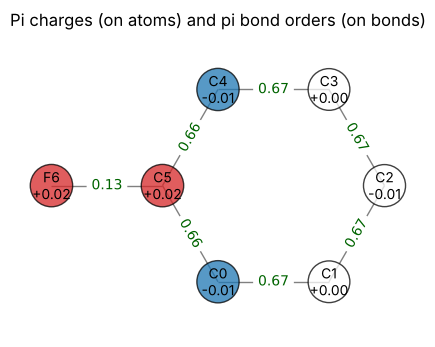

In [45]:
fluorobenzene.plot_pi_population()

In [46]:
# include_halogen_lone_pairs=False: original behavior, F ignored,
# recovers exactly plain benzene (no warning)
fluorobenzene_no_halogen = HMO("c1ccccc1F", include_halogen_lone_pairs=False)
print(fluorobenzene_no_halogen.pi_atom_idx, fluorobenzene_no_halogen.labels,
      fluorobenzene_no_halogen.n_pi_electrons)

[0, 1, 2, 3, 4, 5] ['C0', 'C1', 'C2', 'C3', 'C4', 'C5'] 6


The same halogen on a plain isolated double bond (no need for aromaticity) is handled the same way -- again by combining this fix with the one, already seen, for an isolated double bond (the "Edge case" section above):

In [47]:
vinyl_chloride = HMO("C=CCl")
vinyl_chloride.summary()

SMILES: C=CCl
Pi atoms (3): C0:1, C1:1, Cl2:2
Pi electrons: 4
Total pi energy: E_pi = 4α + 5.1159β
Atomization energy: E_at = 2.1559β
Conjugation energy: E_conj = 0.1559β

 mo_index    x_beta  occupation     role
        2 -1.077957         0.0     LUMO
        1  0.766320         2.0     HOMO
        0  1.791637         2.0 occupied


/tmp/claude-0/-home-claude/39b22db6-d539-5297-8772-4f0a0f2b0ef7/scratchpad/conj_build/_test_shim/pyphyschemtools/huckel.py:760: UserWarning: Atom idx 2 (Cl) is a halogen bonded directly to the conjugated pi system -- its in-plane lone pair is being folded into the pi system as a 2-electron donor, using the 'van_catledge' parameter set's 'halogen' h/k values. This follows the standard Hückel treatment of aryl/vinyl halides, but is a modelling choice, not every textbook treatment includes it -- pass include_halogen_lone_pairs=False to exclude halogens instead (as plain, inert sigma substituents, outside the pi system entirely).
  warnings.warn(


Br was originally tabulated only on the Streitwieser side (`VAN_CATLEDGE_TABLE` had none, since the Van-Catledge (1980) paper doesn't cover bromine) -- `VAN_CATLEDGE_TABLE["Br","halogen"]` therefore carries over, just like `("C","anion")`/`("C","cation")` or `("C","methyl_donor")`, the Streitwieser values as-is, so that `parameter_set="van_catledge"` (the default) also works for Br:

In [48]:
from pyphyschemtools import VAN_CATLEDGE_TABLE, STREITWIESER_TABLE
print("Van Catledge Br:", VAN_CATLEDGE_TABLE[("Br", "halogen")])
print("Streitwieser Br:", STREITWIESER_TABLE[("Br", "halogen")])

Van Catledge Br: (1.5, 0.3, 2)
Streitwieser Br: (1.5, 0.3, 2)


## 21. Rendering with a fixed C-C bond length (pixels)

Every plotting method that draws the molecular skeleton now fixes
the **C-C bond length to a given number of pixels**,
whatever the molecule's size (via the `bond_length_px` parameter):

- `show()`: 80 px by default (the skeleton + hybridization labels stay
  readable, without C=C filling the whole canvas);
- `plot_pi_population()`: 100 px by default (the bond-order and
  charge labels, drawn right on the bonds/atoms, need more room);
- the MO plots (`plot_mo_on_graph()`, `plot_all_mo()`, `plot_mo_list()`,
  and the FMO diagram): 70 px by default.

Let's compare ethylene (the smallest pi molecule we'll handle) and
coronene (one of the largest): the figure size adapts to the
molecule's actual extent, but the C-C bond always renders at the
same size on screen in both cases.

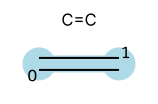

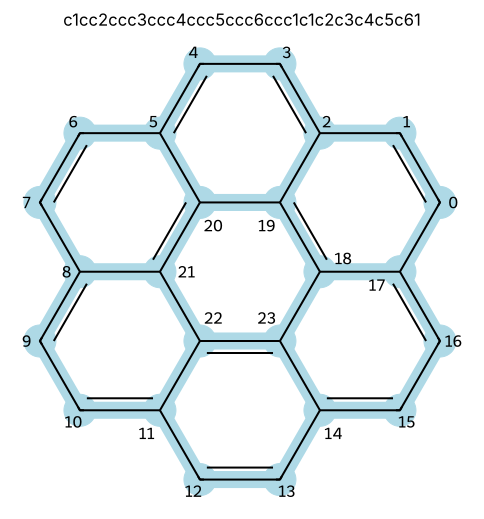

In [49]:
ethylene = HMO('C=C')
coronene = HMO('c1cc2ccc3ccc4ccc5ccc6ccc1c1c2c3c4c5c61')
ethylene.show()
coronene.show()

Ethylene's skeleton is tiny (a single C=C bond) while coronene's
is large (24 pi atoms), but in both cases the C-C bond measures
80 px on screen -- it's the *figure* size that adapts, not the
bond's own size.

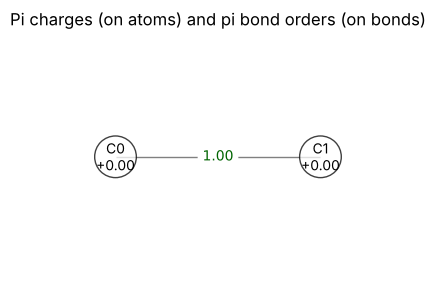

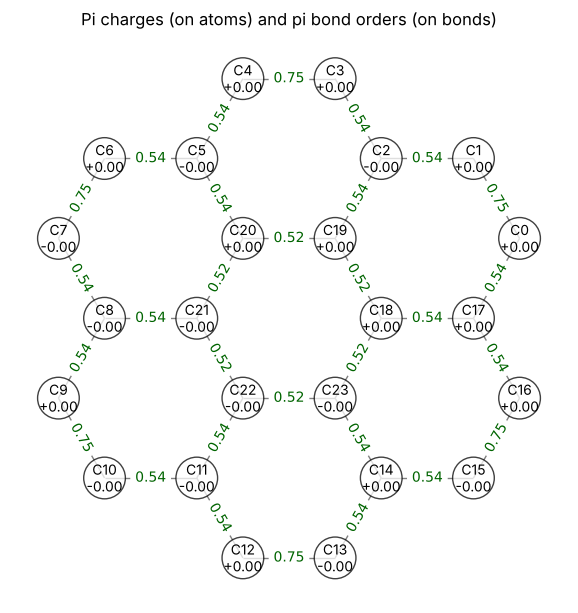

In [50]:
ethylene.plot_pi_population()
coronene.plot_pi_population()

Same idea for `plot_pi_population()`, with a C-C bond at 100 px
by default (a bit larger, so the pi bond-order and charge labels
stay readable).

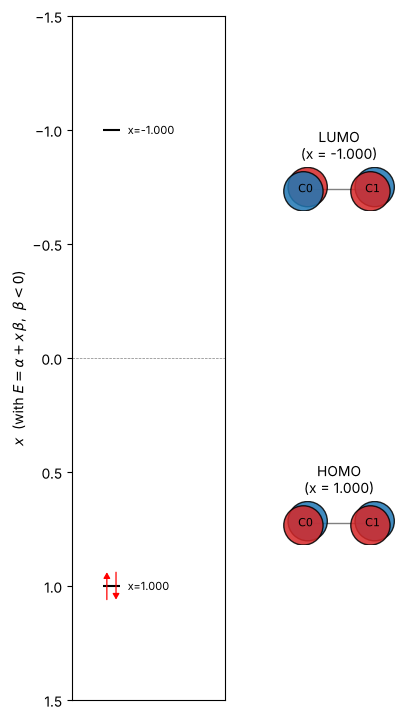

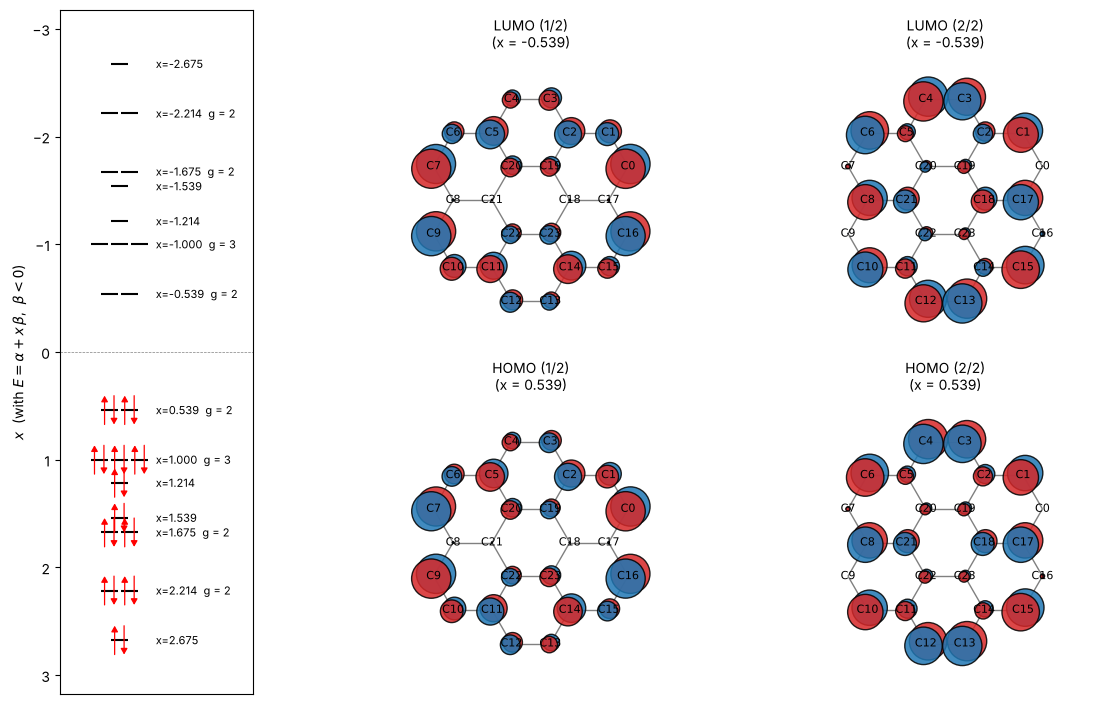

In [51]:
ethylene.plot_energy_diagram('FMO')
coronene.plot_energy_diagram('FMO')

The MO diagram (mode `'FMO'`) always keeps the same **total height**
(700 px), with the LUMO(s) on top and the HOMO(s)/SOMO(s) on the
bottom (350 px each). The width adapts to the number of degenerate
orbitals to display and to the molecule's size, but each MO's C-C
bond always renders at 70 px -- which keeps ethylene's pi MO (a
single bond) from being blown up out of proportion compared to
coronene's.

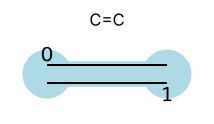

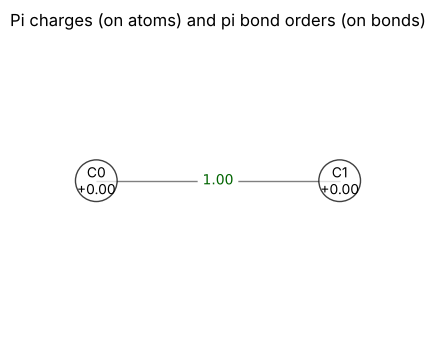

In [52]:
# bond_length_px is adjustable: e.g. larger bonds
# for a molecule you want to present in detail
ethylene.show(bond_length_px=120)
ethylene.plot_pi_population(bond_length_px=160)